<a href="https://colab.research.google.com/github/Raiqueeee/ML/blob/main/Logistic_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Logistic Regression

## Overview
This notebook trains a Logistic Regression model to predict whether a breast tumour is malignant or benign from measurements of cell nuclei. It covers loading data, exploring it, scaling the features, splitting the data, training the model, and evaluating it with classification metrics.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

## Dataset
The Breast Cancer Wisconsin dataset is built into scikit-learn (`sklearn.datasets.load_breast_cancer`). It has 569 samples, 30 features computed from cell nucleus measurements, and a binary target: malignant (0) or benign (1).

In [2]:
cancer = load_breast_cancer(as_frame=True)
X = cancer.data
y = cancer.target
print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("Target names:", list(cancer.target_names))
df = cancer.frame
print(df.head())

Features shape: (569, 30)
Target shape: (569,)
Target names: [np.str_('malignant'), np.str_('benign')]
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         

In [3]:
print(df.describe().T[['mean', 'std', 'min', 'max']].head(10))
print("Class distribution:")
print(pd.Series(y).value_counts())
print("Missing values:", int(df.isnull().sum().sum()))

                              mean         std        min         max
mean radius              14.127292    3.524049    6.98100    28.11000
mean texture             19.289649    4.301036    9.71000    39.28000
mean perimeter           91.969033   24.298981   43.79000   188.50000
mean area               654.889104  351.914129  143.50000  2501.00000
mean smoothness           0.096360    0.014064    0.05263     0.16340
mean compactness          0.104341    0.052813    0.01938     0.34540
mean concavity            0.088799    0.079720    0.00000     0.42680
mean concave points       0.048919    0.038803    0.00000     0.20120
mean symmetry             0.181162    0.027414    0.10600     0.30400
mean fractal dimension    0.062798    0.007060    0.04996     0.09744
Class distribution:
target
1    357
0    212
Name: count, dtype: int64
Missing values: 0


## Preprocessing and Train/Test Split
Logistic Regression works best when features are on a similar scale, so the features are standardised with StandardScaler (fitted on the training data only). The data is split 80/20 with stratification so both classes keep their proportions.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("Training set:", X_train.shape, "Test set:", X_test.shape)

Training set: (455, 30) Test set: (114, 30)


## Model Training
Train a Logistic Regression model on the scaled training set.

In [5]:
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)
print("Model trained. Number of features:", len(model.coef_[0]))

Model trained. Number of features: 30


## Evaluation
Predict on the test set and report accuracy, the classification report, and the confusion matrix.

In [6]:
y_pred = model.predict(X_test_scaled)
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.4f}")
print(classification_report(y_test, y_pred, target_names=cancer.target_names))
print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.9825
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114

Confusion matrix:
[[41  1]
 [ 1 71]]


## Visualization
Confusion matrix heatmap and the largest model coefficients, which show which features push the prediction most strongly.

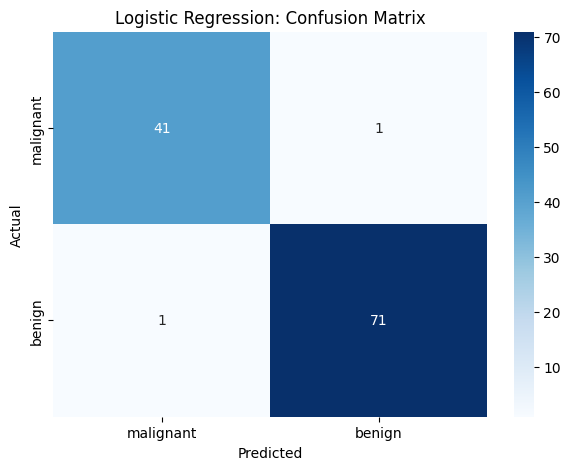

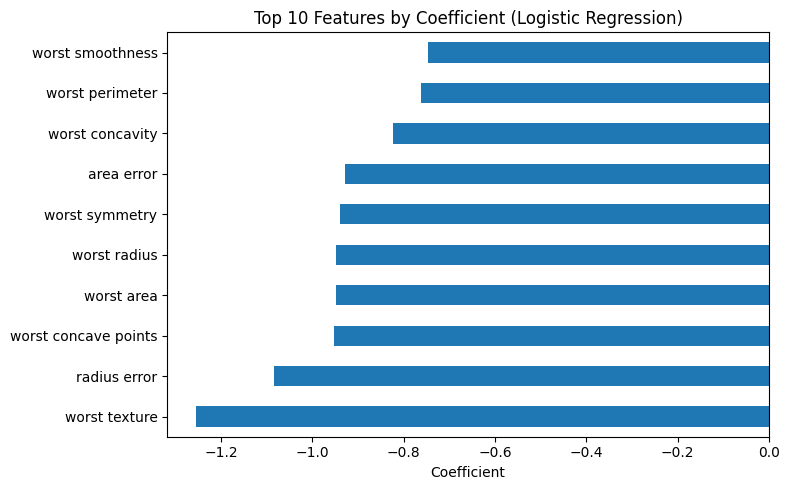

In [7]:
plt.figure(figsize=(7, 5))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues',
            xticklabels=cancer.target_names, yticklabels=cancer.target_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Logistic Regression: Confusion Matrix')
plt.show()

coef = pd.Series(model.coef_[0], index=X.columns).sort_values(key=abs, ascending=False).head(10)
plt.figure(figsize=(8, 5))
coef.sort_values().plot(kind='barh')
plt.xlabel('Coefficient')
plt.title('Top 10 Features by Coefficient (Logistic Regression)')
plt.tight_layout()
plt.show()

## Conclusion
Logistic Regression is a strong, interpretable baseline for this binary classification problem, and the scaled features help it converge well. The classification report shows how well it separates malignant from benign cases.